## Graph Netwrokx

Apa itu graph?

Graph adalah struktur matematika yang terdiri dari vertex/node (titik) dan edge (garis penghubung antar titik). Graph dipakai untuk memodelkan jaringan, misalnya pertemanan di media sosial, jalan antar kota, atau hubungan antar website.

Undirected (tidak berarah): edge tidak punya arah. Jika A terhubung ke B, maka B juga terhubung ke A (seperti pertemanan Facebook).
Directed (berarah): edge punya arah. A→B tidak berarti B→A (seperti follow di Instagram).
Konsep-konsep yang dihitung

1. Matriks adjacency
Matriks n×n. Isi A[i][j] = 1 jika ada edge dari i ke j, selain itu 0. Pada graph undirected matriksnya simetris, sedangkan pada directed tidak harus simetris (baris = asal, kolom = tujuan).

2. Degree

Undirected: jumlah edge yang menempel pada vertex.
Directed: in-degree (jumlah edge masuk), out-degree (jumlah edge keluar), dan total degree = in + out.

3. Rata-rata degree
Undirected: 2m/n. Directed: rata-rata in-degree = rata-rata out-degree = m/n, dan rata-rata total degree = 2m/n. Di sini m adalah jumlah edge dan n jumlah vertex.

4. Density
Seberapa “padat” graph dibanding kemungkinan maksimalnya. Undirected: 2m / n(n-1). Directed: m / n(n-1). Nilainya 0 sampai 1.

5. Rata-rata lintasan terpendek
Jarak terpendek antara dua vertex adalah jumlah edge minimum untuk menghubungkannya. Rata-ratanya dihitung dari semua pasangan vertex yang berbeda. Pada directed, jarak A→B bisa berbeda dari B→A.

6. Koefisien klasterisasi
Mengukur seberapa besar tetangga suatu vertex saling terhubung satu sama lain (kecenderungan membentuk segitiga). Untuk undirected: C(v) = 2 × (jumlah edge antar tetangga) / (k(k-1)), dengan k adalah degree v. Jika k < 2, nilainya 0.

7. Distribusi derajat
Proporsi vertex yang memiliki degree tertentu. P(k) = jumlah vertex berdegree k dibagi n.

In [1]:
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

### Import library

- networkx: membuat dan menganalisis graph.
- numpy: perhitungan numerik (rata-rata).
- pandas: menampilkan hasil dalam bentuk tabel.
- matplotlib: menggambar graph dan grafik.
- Counter: menghitung frekuensi untuk distribusi derajat.

In [2]:
G_u = nx.Graph()
G_u.add_nodes_from([0, 1, 2, 3, 4])
G_u.add_edges_from([(0, 1), (0, 2), (1, 2), (1, 3), (2, 3), (3, 4)])

print("Node :", list(G_u.nodes()))
print("Edge :", list(G_u.edges()))

Node : [0, 1, 2, 3, 4]
Edge : [(0, 1), (0, 2), (1, 2), (1, 3), (2, 3), (3, 4)]


### Graph undirected
nx.Graph() membuat graph kosong tak berarah. add_nodes_from menambah 5 vertex (0-4), dan add_edges_from menambah 6 edge. Struktur graph-nya: segitiga 0-1-2, segitiga 1-2-3, dan vertex 4 menempel hanya ke 3.

In [3]:
G_d = nx.DiGraph()
G_d.add_nodes_from([0, 1, 2, 3, 4])
G_d.add_edges_from([(0, 1), (1, 2), (2, 0), (1, 3), (2, 3), (3, 4), (4, 2)])

print("Node :", list(G_d.nodes()))
print("Edge :", list(G_d.edges()))

Node : [0, 1, 2, 3, 4]
Edge : [(0, 1), (1, 2), (1, 3), (2, 0), (2, 3), (3, 4), (4, 2)]


### Graph directed
nx.DiGraph() membuat graph berarah dengan 7 edge. Ada siklus 0→1→2→0 dan jalur ke 3 lalu 4, yang kembali ke 2 (4→2). Siklus ini membuat setiap vertex bisa mencapai semua vertex lain (strongly connected), sehingga rata-rata lintasan terpendek bisa dihitung.

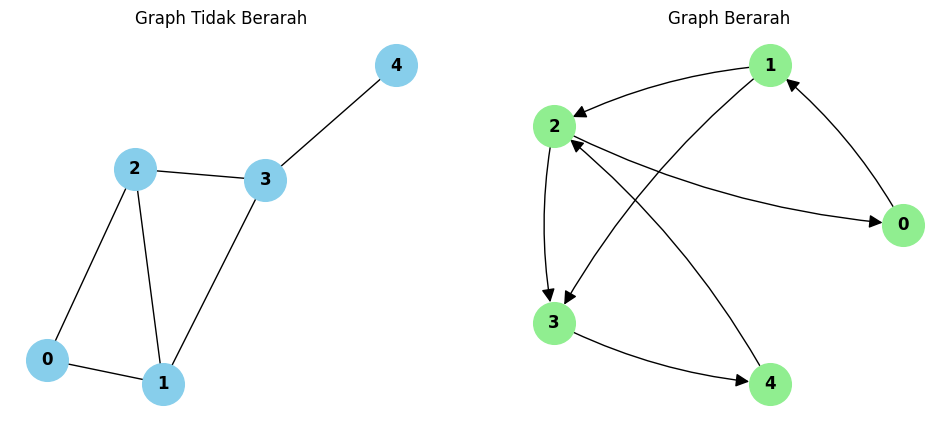

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

pos = nx.spring_layout(G_u, seed=42)
nx.draw(G_u, pos, ax=ax[0], with_labels=True, node_color="skyblue",
        node_size=900, font_size=12, font_weight="bold")
ax[0].set_title("Graph Tidak Berarah")

pos_d = nx.circular_layout(G_d)
nx.draw(G_d, pos_d, ax=ax[1], with_labels=True, node_color="lightgreen",
        node_size=900, font_size=12, font_weight="bold",
        arrows=True, arrowsize=20, connectionstyle="arc3,rad=0.1")
ax[1].set_title("Graph Berarah")

plt.show()

### Visualisasi
Membuat dua gambar berdampingan (subplots(1, 2)). spring_layout dan circular_layout menentukan posisi node, sedangkan seed=42 membuat posisi konsisten setiap dijalankan. arrows=True menampilkan panah pada graph berarah.

In [5]:
nodes = sorted(G_u.nodes())

adj_u = pd.DataFrame(nx.to_numpy_array(G_u, nodelist=nodes, dtype=int),
                     index=nodes, columns=nodes)
adj_d = pd.DataFrame(nx.to_numpy_array(G_d, nodelist=nodes, dtype=int),
                     index=nodes, columns=nodes)

print("Matriks Adjacency - Tidak Berarah")
display(adj_u)
print("\nMatriks Adjacency - Berarah (baris = asal, kolom = tujuan)")
display(adj_d)

Matriks Adjacency - Tidak Berarah


,0,1,2,3,4
0,0,1,1,0,0
1,1,0,1,1,0
2,1,1,0,1,0
3,0,1,1,0,1
4,0,0,0,1,0



Matriks Adjacency - Berarah (baris = asal, kolom = tujuan)


,0,1,2,3,4
0,0,1,0,0,0
1,0,0,1,1,0
2,1,0,0,1,0
3,0,0,0,0,1
4,0,0,1,0,0


### Matriks adjacency
nx.to_numpy_array mengubah graph menjadi matriks, lalu dibungkus DataFrame agar ada label baris dan kolom.

In [6]:
# Undirected
df_deg_u = pd.DataFrame({"Degree": dict(G_u.degree())})
print("Degree - Tidak Berarah")
display(df_deg_u)

# Directed
df_deg_d = pd.DataFrame({
    "In-Degree": dict(G_d.in_degree()),
    "Out-Degree": dict(G_d.out_degree()),
    "Total Degree": dict(G_d.degree())
})
print("Degree - Berarah")
display(df_deg_d)

Degree - Tidak Berarah


,Degree
0,2
1,3
2,3
3,3
4,1


Degree - Berarah


,In-Degree,Out-Degree,Total Degree
0,1,1,2
1,1,2,3
2,2,2,4
3,2,1,3
4,1,1,2


### Degree per vertex
G.degree() memberi degree tiap vertex. Untuk graph berarah dipakai in_degree() dan out_degree().

- Undirected: 0→2, 1→3, 2→3, 3→3, 4→1.
- Directed (in/out): 0→1/1, 1→1/2, 2→2/2, 3→2/1, 4→1/1.

In [7]:
n_u, m_u = G_u.number_of_nodes(), G_u.number_of_edges()
n_d, m_d = G_d.number_of_nodes(), G_d.number_of_edges()

avg_deg_u = np.mean([d for _, d in G_u.degree()])          # = 2m/n
avg_in_d  = np.mean([d for _, d in G_d.in_degree()])       # = m/n
avg_out_d = np.mean([d for _, d in G_d.out_degree()])      # = m/n
avg_tot_d = np.mean([d for _, d in G_d.degree()])          # = 2m/n

print(f"Undirected : rata-rata degree      = {avg_deg_u:.2f}")
print(f"Directed   : rata-rata in-degree   = {avg_in_d:.2f}")
print(f"Directed   : rata-rata out-degree  = {avg_out_d:.2f}")
print(f"Directed   : rata-rata total degree = {avg_tot_d:.2f}")

Undirected : rata-rata degree      = 2.40
Directed   : rata-rata in-degree   = 1.40
Directed   : rata-rata out-degree  = 1.40
Directed   : rata-rata total degree = 2.80


### Rata-rata degree
Menghitung rata-rata dengan np.mean. Hasil: undirected = 12/5 = 2,4. Directed: in = out = 7/5 = 1,4, total degree = 2,8.

In [8]:
print(f"Density Undirected : {nx.density(G_u):.4f}")
print(f"Density Directed   : {nx.density(G_d):.4f}")

Density Undirected : 0.6000
Density Directed   : 0.3500


### Density
nx.density() memakai rumus di atas. Undirected = 12/20 = 0,6. Directed = 7/20 = 0,35.

In [9]:
# Rata-rata keseluruhan graph
print("Rata-rata shortest path (Undirected):",
      round(nx.average_shortest_path_length(G_u), 4))
print("Rata-rata shortest path (Directed)  :",
      round(nx.average_shortest_path_length(G_d), 4))

# Rata-rata per vertex (rata-rata jarak dari vertex tsb ke semua vertex lain)
def avg_sp_per_node(G):
    result = {}
    for node in G.nodes():
        lengths = nx.single_source_shortest_path_length(G, node)
        lengths.pop(node)  # buang jarak ke diri sendiri
        result[node] = np.mean(list(lengths.values()))
    return result

df_sp = pd.DataFrame({
    "Undirected": avg_sp_per_node(G_u),
    "Directed": avg_sp_per_node(G_d)
})
print("\nRata-rata lintasan terpendek per vertex")
display(df_sp.round(4))

Rata-rata shortest path (Undirected): 1.5
Rata-rata shortest path (Directed)  : 1.9

Rata-rata lintasan terpendek per vertex


,Undirected,Directed
0,1.75,2.0
1,1.25,1.5
2,1.25,1.5
3,1.25,2.5
4,2.00,2.0


### Lintasan terpendek
average_shortest_path_length memberi rata-rata untuk seluruh graph. Fungsi avg_sp_per_node menghitung per vertex dengan single_source_shortest_path_length (jarak dari satu vertex ke semua lainnya), membuang jarak ke diri sendiri (jarak 0), lalu merata-ratakan.

In [10]:
df_clust = pd.DataFrame({
    "Undirected": nx.clustering(G_u),
    "Directed": nx.clustering(G_d)
})
print("Koefisien Klasterisasi per vertex")
display(df_clust.round(4))

print(f"\nRata-rata clustering Undirected : {nx.average_clustering(G_u):.4f}")
print(f"Rata-rata clustering Directed   : {nx.average_clustering(G_d):.4f}")
print(f"Transitivity Undirected         : {nx.transitivity(G_u):.4f}")

Koefisien Klasterisasi per vertex


,Undirected,Directed
0,1.0000,0.5000
1,0.6667,0.3333
2,0.6667,0.2500
3,0.3333,0.3333
4,0.0000,0.5000



Rata-rata clustering Undirected : 0.5333
Rata-rata clustering Directed   : 0.3833
Transitivity Undirected         : 0.6000


### Koefisien klasterisasi
nx.clustering() menghitung per vertex, average_clustering() merata-ratakan, dan transitivity() adalah rasio segitiga terhadap triplet pada seluruh graph. Hasil undirected:

- Vertex 0: tetangga {1,2}, keduanya terhubung → 1
- Vertex 1: tetangga {0,2,3}, 2 dari 3 pasangan terhubung → 0,667
- Vertex 2: sama seperti vertex 1 → 0,667
- Vertex 3: tetangga {1,2,4}, 1 dari 3 pasangan terhubung → 0,333
- Vertex 4: degree 1 → 0
- Rata-rata = 0,533

Nilai untuk graph berarah akan muncul di output kode, karena rumusnya lebih kompleks (mempertimbangkan arah edge).

In [11]:
def degree_distribution(degrees, n):
    cnt = Counter(degrees)
    return pd.DataFrame({
        "Degree (k)": sorted(cnt),
        "Jumlah Vertex": [cnt[k] for k in sorted(cnt)],
        "P(k)": [cnt[k] / n for k in sorted(cnt)]
    })

print("Distribusi Degree - Undirected")
display(degree_distribution([d for _, d in G_u.degree()], n_u))

print("Distribusi In-Degree - Directed")
display(degree_distribution([d for _, d in G_d.in_degree()], n_d))

print("Distribusi Out-Degree - Directed")
display(degree_distribution([d for _, d in G_d.out_degree()], n_d))

Distribusi Degree - Undirected


,Degree (k),Jumlah Vertex,P(k)
0,1,1,0.2
1,2,1,0.2
2,3,3,0.6


Distribusi In-Degree - Directed


,Degree (k),Jumlah Vertex,P(k)
0,1,3,0.6
1,2,2,0.4


Distribusi Out-Degree - Directed


,Degree (k),Jumlah Vertex,P(k)
0,1,3,0.6
1,2,2,0.4


### Distribusi derajat (tabel)
Fungsi degree_distribution menghitung berapa vertex yang punya degree k memakai Counter, lalu membaginya dengan n untuk mendapat P(k). Untuk undirected: k=1 → 1 vertex (0,2), k=2 → 1 vertex (0,2), k=3 → 3 vertex (0,6).

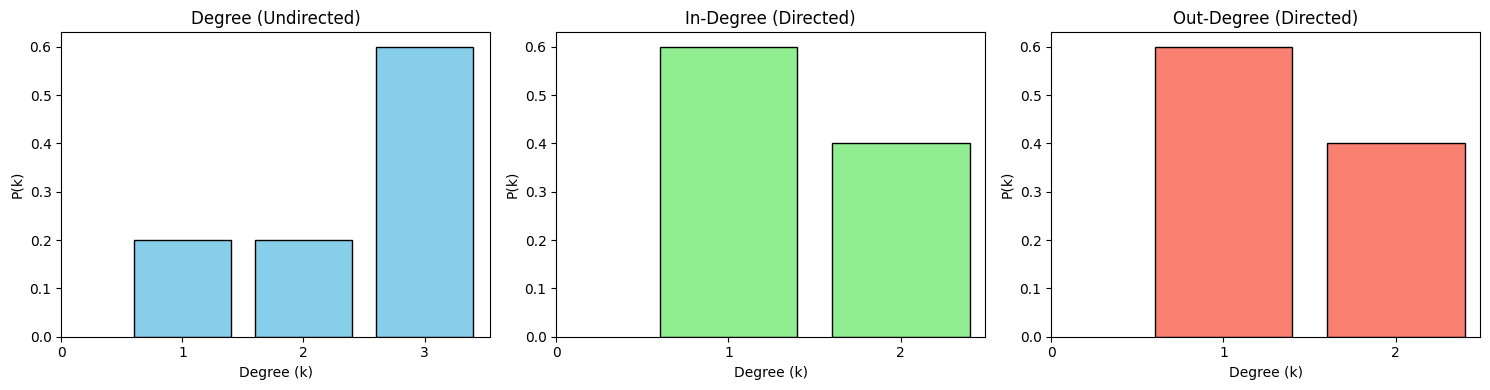

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

data = [
    ([d for _, d in G_u.degree()], "Degree (Undirected)", "skyblue"),
    ([d for _, d in G_d.in_degree()], "In-Degree (Directed)", "lightgreen"),
    ([d for _, d in G_d.out_degree()], "Out-Degree (Directed)", "salmon"),
]

for a, (degs, title, color) in zip(ax, data):
    cnt = Counter(degs)
    ks = sorted(cnt)
    a.bar(ks, [cnt[k] / len(degs) for k in ks], color=color, edgecolor="black")
    a.set_xlabel("Degree (k)")
    a.set_ylabel("P(k)")
    a.set_title(title)
    a.set_xticks(range(0, max(ks) + 1))

plt.tight_layout()
plt.show()

### Distribusi derajat (grafik)
Menampilkan tabel Cell 11 sebagai diagram batang: sumbu x adalah degree k, sumbu y adalah P(k). Ada tiga grafik, yaitu undirected, in-degree, dan out-degree.